<a href="https://colab.research.google.com/github/armdarstiayu/AyuPraktikum/blob/master/Uji_Validitas_Reliabilitas_3TIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uji Validitas dan Reliabilitas Kuesioner Kelas 3 TI A

Topik: penggunaan AI, kebiasaan digital, dan prokrastinasi akademik.

Di Colab, pilih **Runtime > Run all** dan upload `DataKuisioner.csv` atau Excel saat diminta. Untuk menjalankan secara lokal, letakkan CSV di folder yang sama. Hasil pengujian data yang diberikan sudah ada di notebook.

Metode mengikuti contoh dosen: Pearson item-total dan Cronbach's Alpha **per dimensi**. Skor jawaban asli tidak diubah; tidak ada penghapusan butir otomatis atau pembalikan skor karena kunci butir terbalik belum diberikan.

## 1. Import library

Pandas mengolah data, NumPy melakukan perhitungan numerik, SciPy menghitung statistik, dan Matplotlib membuat grafik.

In [9]:
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from IPython.display import display
pd.set_option('display.max_columns', None)

## 2. Membaca data kelas 3 TI A

Pilih butir berdasarkan pola judul [pernyataan], bukan posisi kolom. Kolom durasi gadget dan informasi responden tidak diuji sebagai butir Likert.

In [10]:
nama_file = 'DataKuisioner.csv'
if not Path(nama_file).exists():
    from google.colab import files
    uploaded = files.upload()
    kandidat = [f for f in uploaded if f.lower().endswith(('.csv','.xlsx'))]
    if len(kandidat) != 1:
        raise ValueError('Upload satu file data CSV atau XLSX.')
    nama_file = kandidat[0]
df_awal = pd.read_excel(nama_file) if nama_file.lower().endswith('.xlsx') else pd.read_csv(nama_file, sep=None, engine='python', encoding='utf-8-sig')
df_awal.columns = df_awal.columns.str.strip()
kelas = df_awal['Kelas'].astype(str).str.upper().str.replace(r'\s+', '', regex=True)
df = df_awal.loc[kelas.eq('3TIA')].copy()
kolom_butir = [c for c in df.columns if re.match(r'^.+?\s*\[.+\]$', c)]
butir = df[kolom_butir]
if df.empty or not kolom_butir:
    raise ValueError('Data kelas 3 TI A atau butir tidak ditemukan.')
print('Jumlah responden awal:', len(df_awal))
print('Jumlah responden 3 TI A:', len(df))
print('Jumlah butir:', len(kolom_butir))
print('Sel kosong pada butir:', int(butir.isna().sum().sum()))

Jumlah responden awal: 39
Jumlah responden 3 TI A: 39
Jumlah butir: 29
Sel kosong pada butir: 0


## 3. Konversi skala Likert

STS=1, TS=2, N=3, S=4, SS=5. Jawaban tidak dikenal harus diperiksa, bukan ditebak. Kasus lengkap digunakan agar n sama pada seluruh dimensi.

In [11]:
skala = {'Sangat Tidak Setuju (STS)':1, 'Tidak Setuju (TS)':2, 'Netral (N)':3, 'Setuju (S)':4, 'Sangat Setuju (SS)':5}
teks = butir.apply(lambda s:s.astype('string').str.strip())
num_awal = teks.apply(lambda s:s.map(skala)).astype(float)
gagal = num_awal.isna() & teks.notna() & teks.ne('')
if gagal.any().any():
    raise ValueError('Ada jawaban bukan skala Likert. Periksa data.')
num = num_awal.dropna().copy()
if len(num)<3:
    raise ValueError('Diperlukan minimal tiga kasus lengkap.')
print('Kasus lengkap:', len(num))
print('Kasus dikeluarkan:', len(num_awal)-len(num))
print('Jawaban tidak dikenali:', int(gagal.sum().sum()))

Kasus lengkap: 39
Kasus dikeluarkan: 0
Jawaban tidak dikenali: 0


## 4. Pembagian dimensi dan daftar butir

Kode B1 dimulai ulang pada setiap dimensi. Nama dimensi dan teks asli dipertahankan.

In [12]:
dimensi = {}
for kolom in kolom_butir:
    nama = re.match(r'^(.*?)\s*\[', kolom).group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)
daftar_butir = pd.DataFrame([{'Dimensi':nama, 'Butir':f'B{i}', 'Pernyataan':re.search(r'\[(.*)\]$', c).group(1)} for nama, daftar in dimensi.items() for i,c in enumerate(daftar,1)])
for nama, daftar in dimensi.items():
    print(f'{nama}: {len(daftar)} butir')
display(daftar_butir)

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respons emosional: 5 butir


,Dimensi,Butir,Pernyataan
0,Penggunaan AI pada tugas atau projek kuliah,B1,AI1. Saya menggunakan AI ketika mengerjakan tu...
1,Penggunaan AI pada tugas atau projek kuliah,B2,AI2. Saya menggunakan AI untuk memahami persoa...
2,Penggunaan AI pada tugas atau projek kuliah,B3,AI3. Saya menggunakan AI untuk mencari ide pen...
3,Penggunaan AI pada tugas atau projek kuliah,B4,AI4. Saya menggunakan AI untuk menyusun langka...
4,Penggunaan AI pada tugas atau projek kuliah,B5,AI5. Saya menggunakan AI untuk memperoleh cont...
5,Penggunaan AI pada tugas atau projek kuliah,B6,AI6. Saya menggunakan AI untuk mengembangkan j...
6,Penggunaan AI pada tugas atau projek kuliah,B7,AI7. Saya menggunakan AI untuk meninjau jawaba...
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,PS1. Saya merasa membutuhkan bantuan AI untuk ...
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,PS2. Saya merasa perlu memperoleh saran AI seb...
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,PS3. Saya merasa lebih yakin terhadap jawaban ...


## 5. Uji validitas

Taraf signifikansi 0,05 dua sisi; df=n-2. Valid jika r-hitung > r-tabel, sesuai contoh dosen. Total mencakup butir yang diuji; corrected r memakai total tanpa butir tersebut dan dilaporkan sebagai informasi tambahan. Keputusan menggunakan nilai sebelum dibulatkan.

In [13]:
n = len(num)
df_bebas = n-2
t = stats.t.ppf(.975, df_bebas)
r_tabel = t/np.sqrt(df_bebas+t**2)
def korelasi(a,b):
    if a.nunique()<2 or b.nunique()<2:
        return np.nan, np.nan
    hasil = stats.pearsonr(a,b)
    return float(hasil.statistic), float(hasil.pvalue)
hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i,c in enumerate(daftar,1):
        r,p = korelasi(x[c], total)
        rc,_ = korelasi(x[c], total-x[c])
        keputusan = 'Tidak dapat dihitung' if not np.isfinite(r) else 'Valid' if r>r_tabel else 'Tidak valid'
        hasil_validitas.append({'Dimensi':nama,'Butir':f'B{i}','r hitung':r,'Corrected r':rc,'p-value':p,'Keterangan':keputusan})
tabel_validitas = pd.DataFrame(hasil_validitas)
print(f'n={n}; df={df_bebas}; r-tabel={r_tabel:.6f}')
display(tabel_validitas.round(4))

n=39; df=37; r-tabel=0.316032


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.6617,0.4237,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.5143,0.3466,0.0008,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.6783,0.5172,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.2375,-0.0299,0.1454,Tidak valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.5389,0.3106,0.0004,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.4934,0.2952,0.0014,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.7759,0.6178,0.0000,Valid
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.4944,0.1498,0.0014,Valid
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.5591,0.3110,0.0002,Valid
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.5693,0.3401,0.0002,Valid


## 6. Uji reliabilitas

Cronbach alpha dihitung terpisah untuk setiap dimensi. Batas reliabel 0,70; >=0,80 baik; >=0,90 sangat baik. Alpha jika butir dihapus digunakan untuk evaluasi dan tidak otomatis menghapus pertanyaan.

In [14]:
def cronbach_alpha(x):
    k = x.shape[1]
    v = x.sum(axis=1).var(ddof=1)
    if k<2 or v<=0: return np.nan
    return float(k/(k-1)*(1-x.var(ddof=1).sum()/v))
def kategori(a):
    if not np.isfinite(a): return 'Tidak dapat dihitung'
    return 'Sangat baik' if a>=.90 else 'Baik' if a>=.80 else 'Reliabel' if a>=.70 else 'Tidak reliabel'
hasil_reliabilitas, alpha_dihapus = [], []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({'Dimensi':nama,'Jumlah butir':len(daftar),'Cronbach alpha':a,'Kategori':kategori(a)})
    if len(daftar)>2:
        for i,c in enumerate(daftar,1):
            alpha_dihapus.append({'Dimensi':nama,'Butir':f'B{i}','Alpha jika dihapus':cronbach_alpha(x.drop(columns=c))})
tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
gabung = tabel_validitas.merge(tabel_alpha_dihapus,on=['Dimensi','Butir'],how='left')
display(tabel_reliabilitas.round(4))
display(gabung.round(4))

,Dimensi,Jumlah butir,Cronbach alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.6297,Tidak reliabel
1,Aspek psikologis penggunaan AI pada tugas atau...,7,0.4207,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.3077,Tidak reliabel
3,Prokrastinasi akademik,4,0.1105,Tidak reliabel
4,Respons emosional,5,0.5164,Tidak reliabel


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.6617,0.4237,0.0000,Valid,0.5633
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.5143,0.3466,0.0008,Valid,0.5952
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.6783,0.5172,0.0000,Valid,0.5400
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.2375,-0.0299,0.1454,Tidak valid,0.7055
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.5389,0.3106,0.0004,Valid,0.6030
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.4934,0.2952,0.0014,Valid,0.6067
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.7759,0.6178,0.0000,Valid,0.4884
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.4944,0.1498,0.0014,Valid,0.4115
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.5591,0.3110,0.0002,Valid,0.3223
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.5693,0.3401,0.0002,Valid,0.3122


## 7. Analisis deskriptif dan grafik

Statistik dimensi memakai rata-rata butir per responden (skala 1-5). SD sampel memakai ddof=1; skewness dan kurtosis dikoreksi bias. Kurtosis excess/Fisher: distribusi normal bernilai 0. Grafik menghitung seluruh jawaban butir, bukan persentase responden.

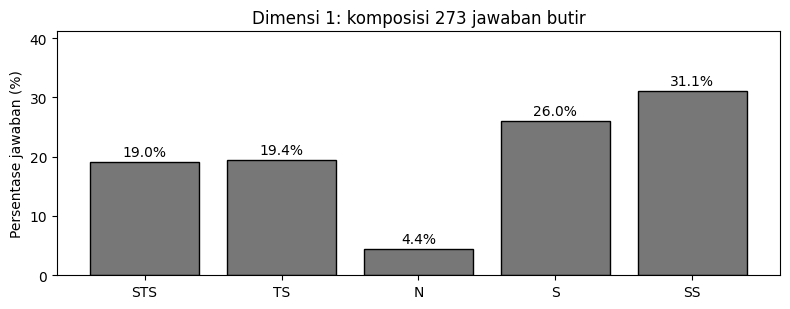

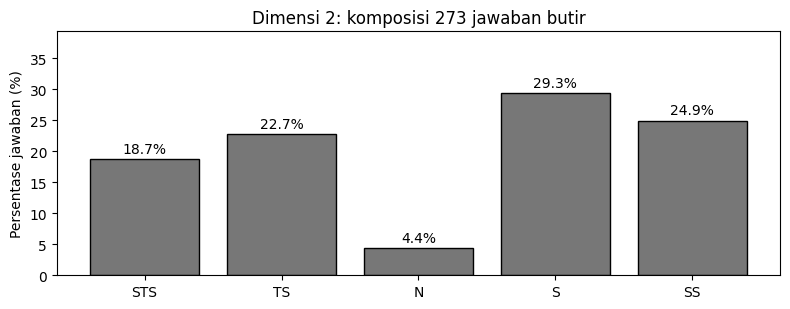

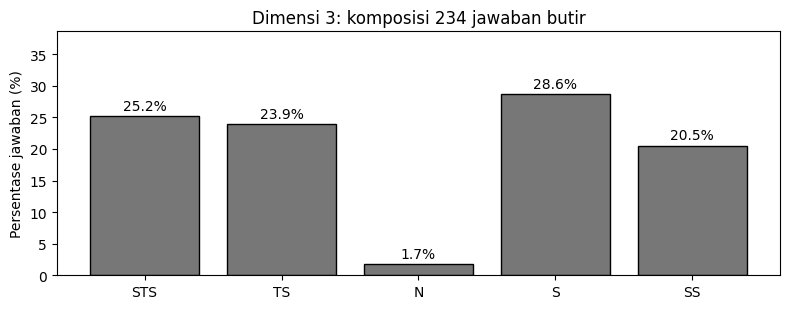

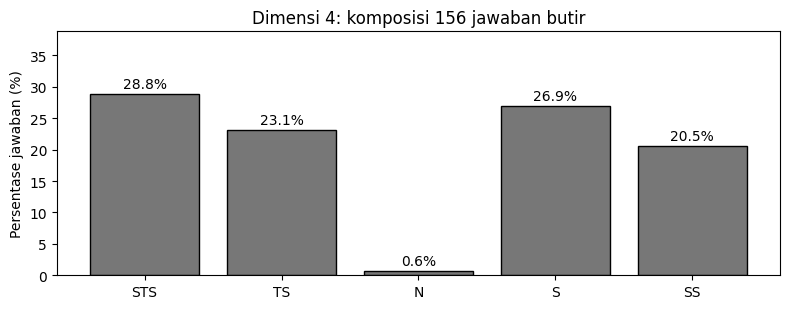

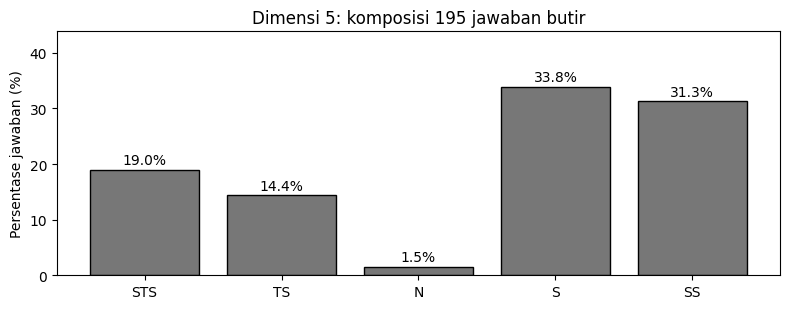

,Dimensi,N,Mean,SD,Skewness,Kurtosis excess
0,Penggunaan AI pada tugas atau projek kuliah,39,3.3077,0.8594,0.1492,-0.5492
1,Aspek psikologis penggunaan AI pada tugas atau...,39,3.1905,0.7108,0.3394,-0.2773
2,Kebiasaan penggunaan teknologi digital,39,2.9530,0.7254,-0.1093,0.9862
3,Prokrastinasi akademik,39,2.8718,0.8189,-0.0753,0.3541
4,Respons emosional,39,3.4410,0.8816,0.0186,-0.9735


In [15]:
folder = Path('output_uji_3TIA')
folder.mkdir(exist_ok=True)
deskriptif, komposisi = [], []
for nomor,(nama,daftar) in enumerate(dimensi.items(),1):
    x = num[daftar]
    rata = x.mean(axis=1)
    deskriptif.append({'Dimensi':nama,'N':len(x),'Mean':rata.mean(),'SD':rata.std(ddof=1),'Skewness':stats.skew(rata,bias=False),'Kurtosis excess':stats.kurtosis(rata,fisher=True,bias=False)})
    frek = pd.Series(x.to_numpy().ravel()).value_counts().reindex(range(1,6),fill_value=0)
    persen = 100*frek/frek.sum()
    for skor in range(1,6):
        komposisi.append({'Dimensi':nama,'Skor':skor,'Frekuensi':int(frek[skor]),'Persen':persen[skor]})
    fig,ax = plt.subplots(figsize=(8,3.2))
    ax.bar(['STS','TS','N','S','SS'],persen,color='#777777',edgecolor='black')
    ax.set_title(f'Dimensi {nomor}: komposisi {len(x)*len(daftar)} jawaban butir')
    ax.set_ylabel('Persentase jawaban (%)')
    ax.set_ylim(0,persen.max()+10)
    for j,v in enumerate(persen): ax.text(j,v+1,f'{v:.1f}%',ha='center')
    fig.tight_layout()
    fig.savefig(folder/f'grafik_dimensi_{nomor}.png',dpi=180)
    plt.show()
    plt.close(fig)
tabel_deskriptif = pd.DataFrame(deskriptif)
tabel_komposisi = pd.DataFrame(komposisi)
display(tabel_deskriptif.round(4))

## 8. Kesimpulan dan ekspor output

Output tersimpan sebagai Excel, CSV dan grafik, lalu dikemas dalam ZIP. Kesimpulan mengikuti hasil perhitungan, tanpa mengubah jawaban responden.

In [16]:
for nama,daftar in dimensi.items():
    v = tabel_validitas.loc[tabel_validitas['Dimensi'].eq(nama)]
    a = tabel_reliabilitas.loc[tabel_reliabilitas['Dimensi'].eq(nama),'Cronbach alpha'].iloc[0]
    tidak = ', '.join(v.loc[v['Keterangan'].ne('Valid'),'Butir']) or 'tidak ada'
    print(f"{nama}: {v['Keterangan'].eq('Valid').sum()}/{len(v)} butir valid; alpha={a:.3f}; {kategori(a)}; butir belum valid: {tidak}.")
print('Total butir valid:', int(tabel_validitas['Keterangan'].eq('Valid').sum()), 'dari', len(tabel_validitas))
tabel_output = {'Validitas':gabung,'Reliabilitas':tabel_reliabilitas,'Deskriptif':tabel_deskriptif,'Komposisi':tabel_komposisi,'Daftar_butir':daftar_butir}
for nama,tabel in tabel_output.items():
    tabel.to_csv(folder/f'{nama}.csv',index=False,encoding='utf-8-sig')
try:
    import openpyxl
except ImportError:
    print('Ekspor Excel dilewati: pasang openpyxl jika diperlukan. CSV tetap tersimpan.')
else:
    with pd.ExcelWriter(folder/'hasil_uji_validitas_reliabilitas.xlsx') as writer:
        for nama,tabel in tabel_output.items(): tabel.to_excel(writer,sheet_name=nama,index=False)
with zipfile.ZipFile('Hasil_Uji_3TIA.zip','w',zipfile.ZIP_DEFLATED) as z:
    for f in sorted(folder.glob('*')): z.write(f,arcname=f.name)
try:
    import google.colab
except ImportError:
    print('Output tersimpan di Hasil_Uji_3TIA.zip')
else:
    from google.colab import files
    files.download('Hasil_Uji_3TIA.zip')

Penggunaan AI pada tugas atau projek kuliah: 6/7 butir valid; alpha=0.630; Tidak reliabel; butir belum valid: B4.
Aspek psikologis penggunaan AI pada tugas atau projek kuliah: 6/7 butir valid; alpha=0.421; Tidak reliabel; butir belum valid: B4.
Kebiasaan penggunaan teknologi digital: 5/6 butir valid; alpha=0.308; Tidak reliabel; butir belum valid: B6.
Prokrastinasi akademik: 4/4 butir valid; alpha=0.111; Tidak reliabel; butir belum valid: tidak ada.
Respons emosional: 5/5 butir valid; alpha=0.516; Tidak reliabel; butir belum valid: tidak ada.
Total butir valid: 26 dari 29


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>